# Part 3 - Cellpose

In [29]:
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
import pandas as pd
import numpy as np
from cellpose import models as cellpose_models
from skimage.measure import regionprops_table

DATA = Path("data/segmentation")

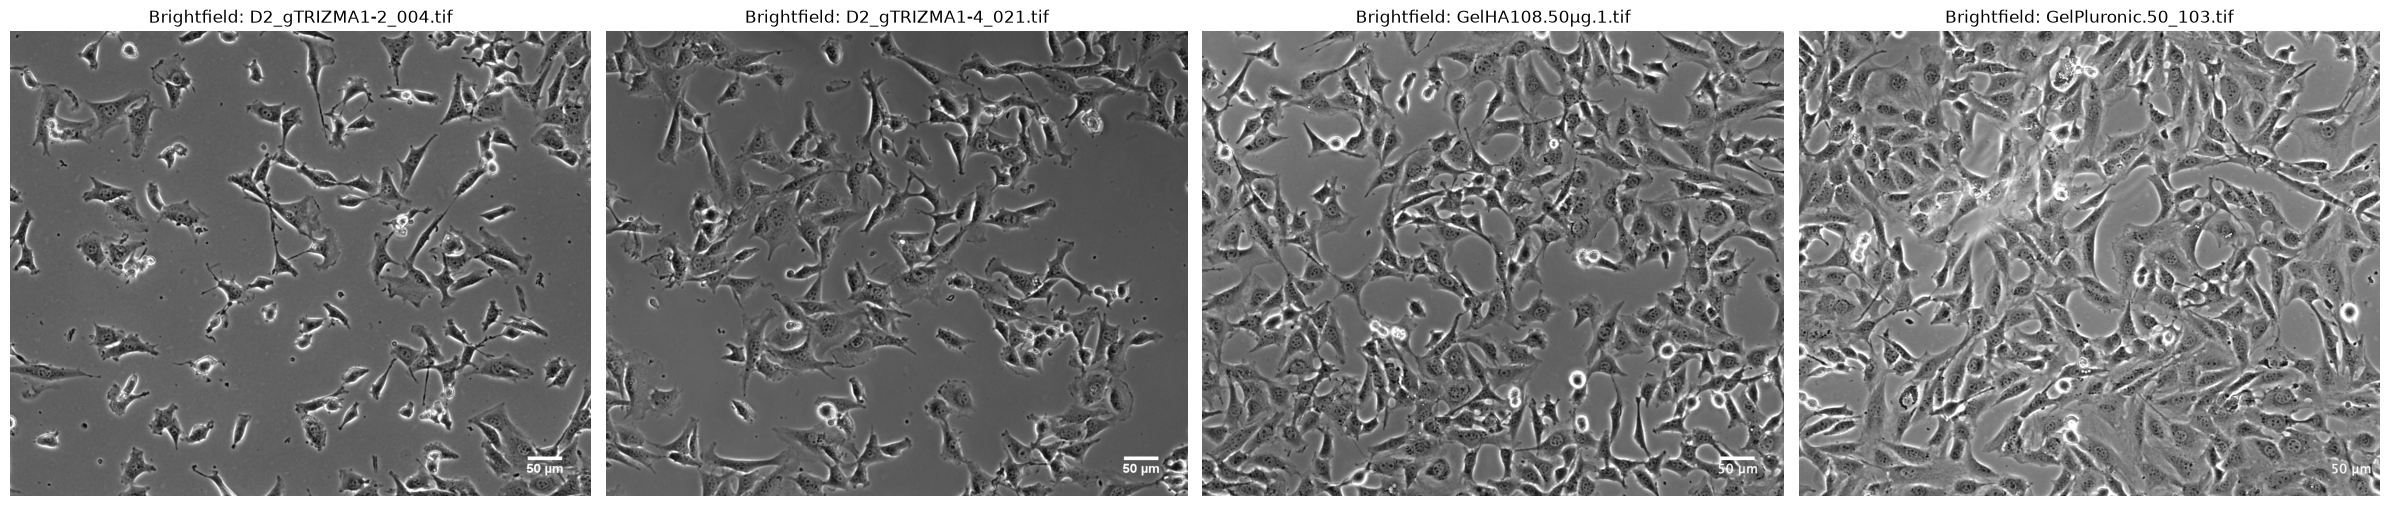

In [24]:
brightfield_files = sorted((DATA / 'brightfield').glob('*'))

fig, ax = plt.subplots(1, 4, figsize=(24, 5))

for i in range(4):
  sample = brightfield_files[5+i]
  ax[i].imshow(Image.open(sample), cmap='gray')
  ax[i].set_title(f'Brightfield: {sample.name}')
  ax[i].axis('off')

fig.tight_layout()
plt.show()

In [27]:
CELLPOSE_PARAMETER_SETS = {
  'default': {
    'model': 'cpsam',
    'flow_threshold': 0.4,
    'cellprob_threshold': 0.0,
    'min_size': 15,
  },
  'sensitive': {
    'model': 'cpsam',
    'flow_threshold': 0.2,
    'cellprob_threshold': -1.0,
    'min_size': 5,
  },
  'conservative': {
    'model': 'cpsam',
    'flow_threshold': 0.8,
    'cellprob_threshold': 0.5,
    'min_size': 30,
  },
}

CELLPOSE_SETTING = 'default'
CELLPOSE_PARAMS = CELLPOSE_PARAMETER_SETS[CELLPOSE_SETTING]
display(pd.DataFrame(CELLPOSE_PARAMETER_SETS).T)
print(f'Selected Cellpose setting: {CELLPOSE_SETTING}')

,model,flow_threshold,cellprob_threshold,min_size
default,cpsam,0.4,0.0,15
sensitive,cpsam,0.2,-1.0,5
conservative,cpsam,0.8,0.5,30


Selected Cellpose setting: default


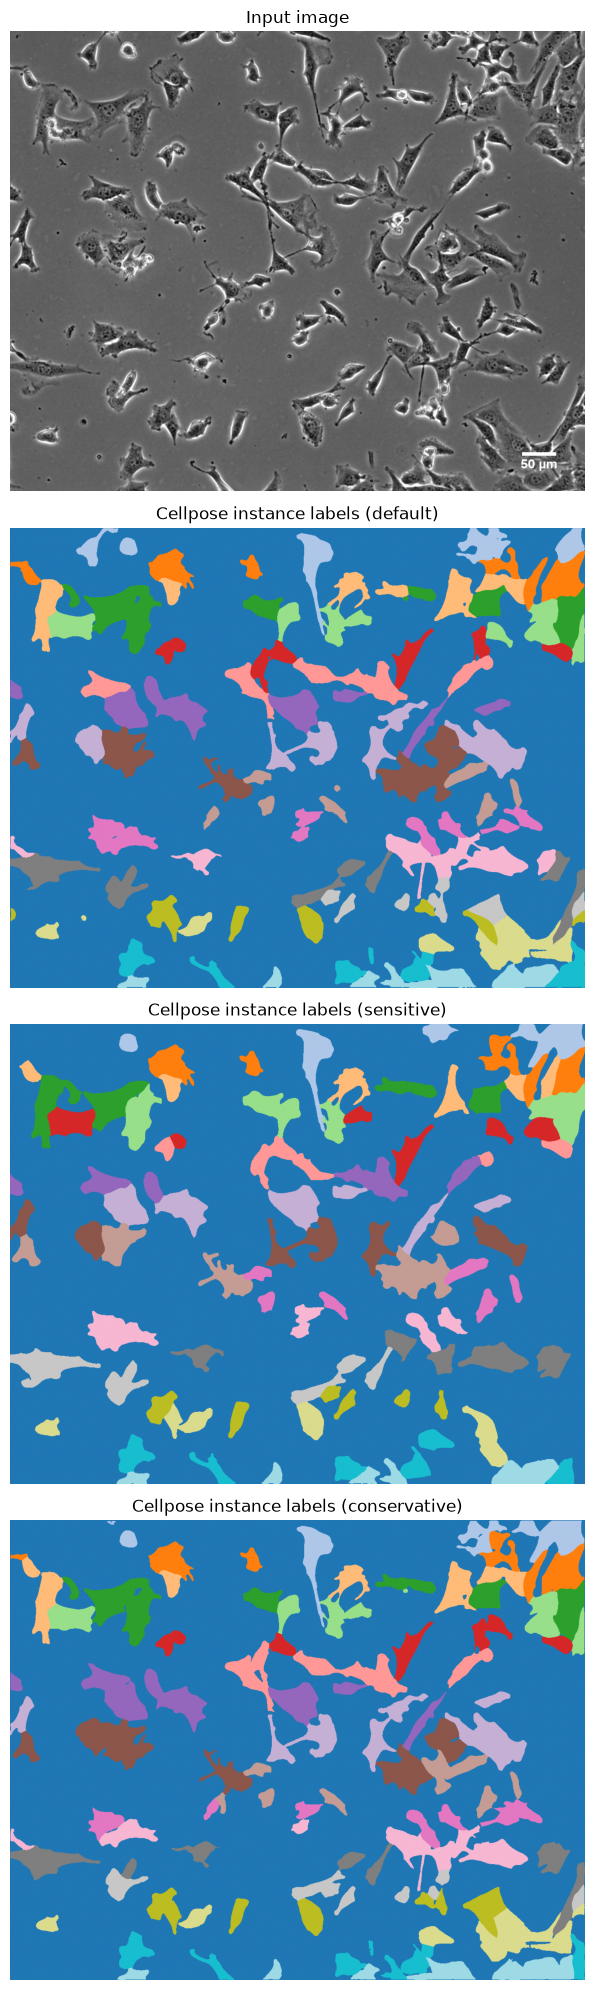

In [39]:
sample = brightfield_files[5]
CELLPOSE_SETTING = 'conservative'
CELLPOSE_PARAMS = CELLPOSE_PARAMETER_SETS[CELLPOSE_SETTING]

cellpose_masks = None
cellpose_image = None

cellpose_model = cellpose_models.CellposeModel(
  gpu=True,
  pretrained_model=CELLPOSE_PARAMS['model'],
)

cellpose_image = np.asarray(
  Image.open(sample).convert('L'),
  dtype=np.float32,
)

CELLPOSE_PARAMS = CELLPOSE_PARAMETER_SETS['default']

cellpose_result_default = cellpose_model.eval(
    cellpose_image,
    channels=[0, 0],
    diameter=None,
    flow_threshold=CELLPOSE_PARAMS['flow_threshold'],
    cellprob_threshold=CELLPOSE_PARAMS['cellprob_threshold'],
    min_size=CELLPOSE_PARAMS['min_size'],
)

CELLPOSE_PARAMS = CELLPOSE_PARAMETER_SETS['sensitive']

cellpose_result_sensitive = cellpose_model.eval(
    cellpose_image,
    channels=[0, 0],
    diameter=None,
    flow_threshold=CELLPOSE_PARAMS['flow_threshold'],
    cellprob_threshold=CELLPOSE_PARAMS['cellprob_threshold'],
    min_size=CELLPOSE_PARAMS['min_size'],
)

CELLPOSE_PARAMS = CELLPOSE_PARAMETER_SETS['conservative']

cellpose_result_conservative = cellpose_model.eval(
    cellpose_image,
    channels=[0, 0],
    diameter=None,
    flow_threshold=CELLPOSE_PARAMS['flow_threshold'],
    cellprob_threshold=CELLPOSE_PARAMS['cellprob_threshold'],
    min_size=CELLPOSE_PARAMS['min_size'],
)

figure, axes = plt.subplots(4, 1, figsize=(12, 20))
axes[0].imshow(cellpose_image, cmap='gray')
axes[0].set_title('Input image')

axes[1].imshow(cellpose_result_default[0], cmap='tab20')
axes[1].set_title('Cellpose instance labels (default)')

axes[2].imshow(cellpose_result_sensitive[0], cmap='tab20')
axes[2].set_title('Cellpose instance labels (sensitive)')

axes[3].imshow(cellpose_result_conservative[0], cmap='tab20')
axes[3].set_title('Cellpose instance labels (conservative)')

for axis in axes:
    axis.axis('off')

plt.tight_layout()
plt.show()

# Conclusion

I would say all modes have some errors. It's most noticeable when looking at the small cell in top-left (A, green border) and a large cell at bottom-left (B, red border):

![](pics/image.png)

In default mode, the cell A is annotated as single cell. I agree with this annotation as I see only one nucleus there. Cell B though seems to have the lower "tentacle" part. The shape of it is quite rough, as well as shapes of other cells.

In sensitive mode, shapes are better, but cell A is now split between two cells.

In conservative mode, shapes are worse than in default.

I would say default makes most sense biologically, but additional human verification is needed. But I'm not experienced in cell annotation 🤷‍♂️